# 从单因子到两因子：同信号、双收获范式的规范研究

这是一份研究方法教学 notebook。目标是在同一数据、同一因子、同一信号下，分别研究截面相对强弱与时序方向配置，再检验动量与展期的增量价值。**研究完成不要求找到改善。**

全部研究配置、关键代码、图表和结论在本文件；辅助区只承载连续状态、持仓记账、统计抽样等复杂计算。请从仓库根目录使用 Conda base，执行“重启内核并运行全部”。运行中会保存检查点与可校验的实际权重快照。

**最终保留样本：2025—2026 年属于整个多因子研发项目，本研究不使用。** 2011—2024 年只能称为“开发期内部样本外”；此前已有探索，不能恢复为未接触样本。不得因结果不好修改截止日期、翻转方向或扩展候选。


In [1]:
from pathlib import Path
from dataclasses import replace
from contextlib import redirect_stdout
from types import SimpleNamespace
import datetime as dt
import hashlib
import io
import itertools
import json
import logging
import subprocess
import time
import warnings
import sys
import os

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'factors').is_dir() and (p/'data').is_dir())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from factors import presets
from factors.models import DataRequirement, UniverseSpec, LabelSpec
from factors.labels import LabelBuilder
from factors.library.basic import MomentumFactor, RollYieldFactor
from factors.preprocess.scale import FittedPooledScalar, CrossSectionalZscore
from factors.diagnostic_portfolio.models import RebalanceConfig, RiskConfig, ConstraintConfig, CostConfig, DiagnosticPortfolioSpec
from factors.profiles import market_rank_ls, ts_inv_vol_target_vol
from research.experiments.single_to_two_factor.support import (
    MatrixPanel, simulate_signal, combine_positions, evaluate_target_weights, score_run,
    paired_block_bootstrap, assert_development_only, protocol_fingerprint,
    frame_fingerprint, to_long, save_json, save_result, verify_snapshot,
)
from research.experiments.single_to_two_factor.temporal import validation_candidates

pd.set_option('display.max_rows', 16)
pd.set_option('display.max_columns', 12)
plt.rcParams.update({'figure.dpi': 95, 'savefig.dpi': 95, 'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'DejaVu Sans'], 'axes.unicode_minus': False})
# 计算警告保存为产物；第三方日期库的弃用提醒不影响研究口径。
warnings.filterwarnings('ignore', category=FutureWarning)
logging.getLogger('factors.library.basic').setLevel(logging.ERROR)
STARTED = time.perf_counter()


## 1．冻结研究章程

经济假设：过去收益与期限结构可能包含不同但有重叠的信息；低相关和组合改善都是待检验命题。

统计假设：控制另一个因子后仍存在增量预测关系。投资假设：共同使用信号能在相同约束和成本下产生有意义的增量价值。二者不能互相替代。

主要比较预先固定为两种 profile 各自的 **S−M、S−C**，共四项；持仓组合 P、自适应择优和跨 profile 对照属于次级证据。教学实用幅度为 Sharpe 改善 0.1；结果不确定时写“证据不足”，不得更换主要命题。

动量与 carry 的文献只是机制依据，不能直接证明当前短周期截面／时序实现有效：[TSMOM 原始研究说明](https://www.aqr.com/Insights/Datasets/Time-Series-Momentum-Original-Paper-Data)、[Carry 原文](https://www.nber.org/system/files/working_papers/w19325/w19325.pdf)、[库存与商品收益研究](https://www.nber.org/papers/w13249)。


In [2]:
# 唯一研究协议。改变任何内容都产生新指纹，旧结果不能混入。
PROTOCOL = {
    'version': '1.0', 'start_date': '2000-01-01', 'end_date': '2024-12-31',
    'research_start': 2005, 'first_test_year': 2011, 'last_test_year': 2024,
    'training_years': 5, 'validation_years': 1,
    'asset_classes': ['agricultural', 'nonferrous_metal', 'energy_chemical', 'ferrous_metal'],
    'universe': {'min_listing_days': 126, 'liquidity_lookback': 20, 'min_average_volume': 10000, 'min_data_coverage': 0.5},
    'momentum_windows': [10, 20, 60], 'reference_momentum': 20,
    'momentum_vol_window': 60, 'momentum_vol_min': 60,
    'carry_bands': [[0,365], [14,180], [14,365]], 'reference_carry': [14,365],
    'carry_combination': 'near_dominant', 'carry_price': 'Close', 'carry_volnorm': False,
    'horizons': [1,5,20], 'primary_horizon': 5, 'clip': 3.0,
    'alphas': [0.25,0.50,0.75], 'reference_alpha': 0.5,
    'interval': 5, 'min_products': 10, 'max_product_weight': 0.2,
    'risk': {'volatility_lookback': 60, 'volatility_min_periods': 60,
             'covariance_lookback': 120, 'covariance_min_periods': 100, 'target_volatility': 0.1},
    'max_gross': 2.5, 'max_volatility_scaler': 2.5, 'annualization': 252,
    'cost_rate': 0.0001, 'missing_return_policy': 'raise',
    'min_validation_observations': 200, 'tie_tolerance': 1e-12,
    'bootstrap': {'block_size': 20, 'reps': 5000, 'seed': 20261124, 'family_size': 4, 'practical_delta': 0.1},
    'challenges': {'intervals': [1,20], 'offsets': [0,1,2,3,4],
                   'cost_bps': [0,0.3,1,3], 'bootstrap_blocks': [5,60], 'leave_top_products': 3,
                   'risk_windows': [[30,30,60,50],[120,100,240,200]]},
}
PROTOCOL_ID = protocol_fingerprint(PROTOCOL)
NOTEBOOK_PATH = ROOT/'research/notebooks/202611/single-to-two-factor_research_standard.ipynb'
# 指纹只包含代码源，不包含执行输出；辅助代码变化也强制产生新检查点。
source = json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8-sig'))
code_sources = ''.join(''.join(c['source']) for c in source['cells'] if c['cell_type']=='code')
helper_sources = ''.join(p.read_text(encoding='utf-8-sig') for p in sorted((ROOT/'research/experiments/single_to_two_factor').glob('*.py')))
from importlib.metadata import version
runtime_versions={'python':sys.version,'executable':sys.executable,
                  **{name:version(name) for name in ['numpy','pandas','scipy','statsmodels','matplotlib','pyarrow','arch']}}
core_commit=subprocess.check_output(['git','rev-parse','HEAD'],text=True).strip()
core_diff=subprocess.check_output(['git','diff','--','factors','data'],text=True,encoding='utf-8')
environment_text=(ROOT/'environment.yml').read_text(encoding='utf-8-sig')
CODE_ID = hashlib.sha256((code_sources+helper_sources+core_commit+core_diff+environment_text+
                         json.dumps(runtime_versions,sort_keys=True)).encode('utf-8')).hexdigest()
ARTIFACT_ROOT = ROOT/'research/artifacts/single_to_two_factor'/PROTOCOL_ID[:12]
ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
save_json(ARTIFACT_ROOT/'protocol.json', PROTOCOL)
print('协议:', PROTOCOL_ID, '\n代码:', CODE_ID, '\n截止:', PROTOCOL['end_date'], '\n解释器:', sys.executable)
display(pd.DataFrame({'共享原始因子与参数':['M:20日；C:14—365日'], '共同预测期限':['1、5、20日；主要5日'], '两种收获':['截面排名多空；时序逆波动率＋目标波动率']}))


协议: 1fc83d955453a84174bc0f955b0ee73542b1829bc0fd41bb48720d7a285b1c87 
代码: 8502926b247b251ced3c0c46becd8f33f877c0c51b333b355bbc592524eeddc0 
截止: 2024-12-31 
解释器: C:\Users\Jesse\AppData\Local\anaconda3\python.exe


,共享原始因子与参数,共同预测期限,两种收获
0,M:20日；C:14—365日,1、5、20日；主要5日,截面排名多空；时序逆波动率＋目标波动率


## 2．投资问题与时间轴

同一个正信号，在截面中表示“相对其他品种较强”，在时序中表示“自身偏多”。共享 RMS 缩放不去均值，避免把时序多空零点改成截面均值。

| 时点 | 可做的事 | 禁止的事 |
|---|---|---|
| t 日收盘后 | 观察截至 t 的价格、持仓、期限结构；形成研究权重 | 用 t+1 收益判断 t 是否有资格 |
| 全局下一交易日 | 实现 t 的持仓收益与成本 | 漏算首次建仓或跨年切换成本 |
| t+h 之后 | 标签成熟，可进入之后的历史估计 | 在标签尚未成熟时训练 |

预测期限 h、调仓间隔、实际持仓存续是不同概念。这里持仓每 5 个全局交易时点更新，标签统一检验 1／5／20 日。理想化的收盘决策与下一日完整收益，并不证明真实市场可以按该价格成交。


## 3．先审计数据，再观察表现

只请求 2024 年以前的数据。品种按历史准入变化，不能只选择今天仍存续或历史表现好的品种。分类仅用于界定商品范围与归因，不用后验收益筛选品种。

品种分类采用当前静态标签用于范围与归因，不声称拥有历史分类版本。所有真实行情和因子输入仍严格截断至 2024 年。


In [3]:
facade = presets.make_facade()
classification = facade.rule_query.classification.get_classification()
classified_products = set(classification.loc[classification.asset_class.isin(PROTOCOL['asset_classes']), 'product'])
products = tuple(p for p in presets.default_products(facade) if p in classified_products
                 and pd.Timestamp(facade.rule_query.get_list_date_product(p)) <= pd.Timestamp(PROTOCOL['end_date']))
with redirect_stdout(io.StringIO()) as loading_log:
    dataset = presets.build_dataset(products=products,
        start_date=dt.date.fromisoformat(PROTOCOL['start_date']), end_date=dt.date.fromisoformat(PROTOCOL['end_date']),
        sources=(DataRequirement('main_panel'), DataRequirement('term_structure'), DataRequirement('classification')),
        universe=UniverseSpec(**PROTOCOL['universe']))
assert_development_only(dataset.main_panel, dataset.auxiliary['term_structure'])
if not dataset.quality.is_valid:
    raise ValueError(f'主面板 schema 无效：{dataset.quality.errors}')
base_panel = MatrixPanel.from_dataset(dataset)
raw_returns = base_panel.returns
raw_eligible = base_panel.eligible
missing_products = sorted(set(products)-set(raw_returns.columns))
save_json(ARTIFACT_ROOT/'data_audit.json', {'requested_products': products, 'missing_products': missing_products,
    'quality_warnings': dataset.quality.warnings, 'last_observed_date': str(raw_returns.index.max()),
    'request_end': PROTOCOL['end_date'], 'load_log': loading_log.getvalue()})
print(f'请求 {len(products)} 个商品；返回 {len(raw_returns.columns)} 个；缺失：{missing_products}')
print(f'实际时间：{raw_returns.index.min().date()} 至 {raw_returns.index.max().date()}；主面板 {len(dataset.main_panel):,} 行')
display(classification.loc[classification['product'].isin(raw_returns.columns)].groupby('asset_class').size().rename('品种数').to_frame())


请求 79 个商品；返回 79 个；缺失：[]
实际时间：2000-01-04 至 2024-12-31；主面板 201,967 行


,品种数
asset_class,
agricultural,34
energy_chemical,23
ferrous_metal,9
nonferrous_metal,13


有收益品种             动态准入品种        
                mean min max       mean min max
timestamp                                      
2000        5.355372   0   6   0.921488   0   2
2001        5.942623   3   6   1.692623   0   3
2002        6.000000   6   6   3.854772   2   5
2003        6.755187   5   7   5.531120   5   7
2004        8.242798   7  11   6.522634   5   8
...              ...  ..  ..        ...  ..  ..
2020       56.403292  50  60  47.514403  45  51
2021       59.283951  56  62  53.012346  50  55
2022       58.033058  55  62  52.123967  50  54
2023       59.719008  57  63  52.954545  51  57
2024       64.041322  61  67  57.338843  55  59

[25 rows x 6 columns]

,排除格子数
min_average_volume,44775
min_data_coverage,13848
min_listing_days,6671
min_daily_volume,5591
min_open_interest,5591
delist_date,6


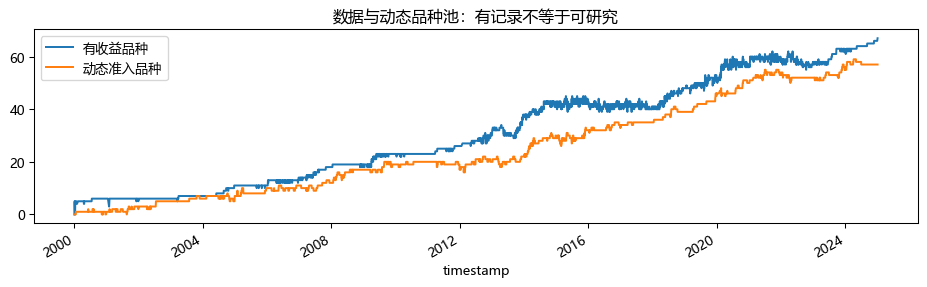

In [4]:
# 数据缺口在全局网格显式可见，不用向前填充收益。
input_audit = pd.DataFrame({'有收益品种': raw_returns.notna().sum(axis=1), '动态准入品种': raw_eligible.sum(axis=1)})
display(input_audit.groupby(input_audit.index.year).agg(['mean','min','max']))
reasons = dataset.universe.exclude_reason.fillna('').str.split(';').explode()
display(reasons.loc[reasons.ne('')].value_counts().rename('排除格子数').to_frame())
input_audit.plot(figsize=(12,3), title='数据与动态品种池：有记录不等于可研究'); plt.show()


## 4．原始因子、共同样本与完整标签

动量为累计真实收益除以当期历史波动率与 √lookback；展期为近月／主力价格比按 DTE 差年化。所有窗口和方向固定，禁止先看后续表现再翻转符号。

共同资格要求：历史动态准入、六个候选信号均有效、时序波动率与协方差历史充足。少于 10 个共同品种时停止新建头寸；已退出品种归零，其他旧持仓按原规则等待计划调仓日。这个共同样本有意牺牲覆盖率，以隔离比较中的样本变化。


,M_010,M_020,M_060,C_000_365,C_014_180,C_014_365,共同准入品种数,动态准入品种数,允许新建
timestamp,,,,,,,,,
2000,0.752336,0.752336,0.752336,0.684579,0.067757,0.838785,0.037,0.921,0.0
2001,0.798064,0.798064,0.798064,0.885892,0.741355,0.858921,1.029,1.693,0.0
2002,0.918396,0.918396,0.918396,0.933887,0.783541,0.92462,2.913,3.855,0.0
2003,0.948548,0.948548,0.948548,0.947204,0.773424,0.917171,3.975,5.531,0.0
2004,0.976484,0.976484,0.976484,0.92284,0.768705,0.882853,4.737,6.523,0.0
...,...,...,...,...,...,...,...,...,...
2020,0.997434,0.997434,0.997434,0.856153,0.753736,0.767607,34.296,47.514,1.0
2021,1.0,1.0,1.0,0.850914,0.722643,0.730125,37.284,53.012,1.0
2022,1.0,1.0,1.0,0.848387,0.699615,0.707839,35.785,52.124,1.0


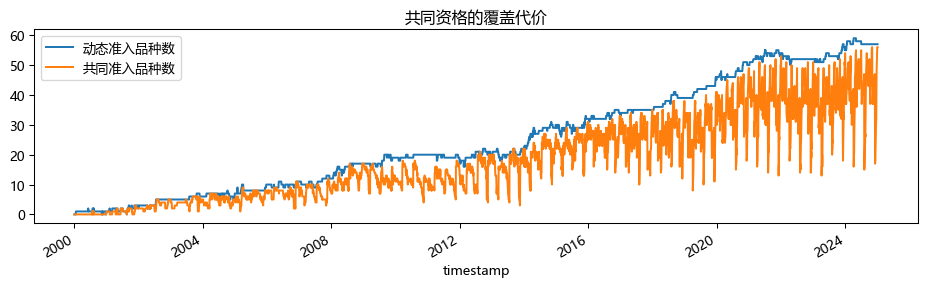

实际输入指纹: 60ec190500a3ca5b4e37a640331783f41f8c030c29364b84ad2127ce834718ab 
本次产物: D:\量化策略\CTA策略\early-bird-alpha\research\artifacts\single_to_two_factor\1fc83d955453\5f79da03c7de4dd7


In [5]:
raw_factors = {}
factor_warnings = {}
for lookback in PROTOCOL['momentum_windows']:
    key = f'M_{lookback:03}'
    factor = MomentumFactor(lookback, volnorm=True, vol_lookback=PROTOCOL['momentum_vol_window'], vol_min_periods=PROTOCOL['momentum_vol_min'])
    raw_factors[key] = factor.compute(dataset.main_panel).unstack('product').reindex_like(raw_returns)
for low, high in PROTOCOL['carry_bands']:
    key = f'C_{low:03}_{high:03}'
    factor = RollYieldFactor(combination=PROTOCOL['carry_combination'], near_dte_min=low, far_dte_max=high,
                             price_col=PROTOCOL['carry_price'], volnorm=PROTOCOL['carry_volnorm'])
    raw_factors[key] = factor.compute(dataset.auxiliary['term_structure']).unstack('product').reindex_like(raw_returns)
    factor_warnings[key] = list(factor.warnings)

volatility = raw_returns.rolling(PROTOCOL['risk']['volatility_lookback'], min_periods=PROTOCOL['risk']['volatility_min_periods']).std(ddof=1)
risk_valid = volatility.gt(0) & raw_returns.rolling(PROTOCOL['risk']['covariance_lookback'], min_periods=1).count().ge(PROTOCOL['risk']['covariance_min_periods'])
common_eligible = raw_eligible & risk_valid
for values in raw_factors.values():
    common_eligible &= np.isfinite(values)
# 共同池不足时只禁止新建，不能在非调仓日强迫所有剩余持仓平仓。
# 输入信号在这些日期设为 NaN；资格本身仍保留供强制退出规则判断。
new_entry_allowed = common_eligible.sum(axis=1).ge(PROTOCOL['min_products'])
panel = base_panel.with_eligible(common_eligible)

coverage = pd.concat({key: values.notna().where(raw_eligible).mean(axis=1) for key, values in raw_factors.items()}, axis=1)
coverage['共同准入品种数'] = common_eligible.sum(axis=1)
coverage['动态准入品种数'] = raw_eligible.sum(axis=1)
coverage['允许新建'] = new_entry_allowed
coverage.to_parquet(ARTIFACT_ROOT/'coverage.parquet')
display(coverage.groupby(coverage.index.year).mean().round(3))
coverage[['动态准入品种数','共同准入品种数']].plot(figsize=(12,3), title='共同资格的覆盖代价'); plt.show()

# LabelBuilder 输入先补齐交易日，避免 shift 跨过缺失日期。
label_dataset = SimpleNamespace(main_panel=to_long(raw_returns, 'True_Return').to_frame())
label_specs = [LabelSpec(f'fwd_{h}', h, min_valid_obs=h) for h in PROTOCOL['horizons']]
labels = LabelBuilder(label_specs, label_dataset).build().labels
label_matrices = {h: labels[f'fwd_{h}'].unstack('product').reindex_like(raw_returns) for h in PROTOCOL['horizons']}
for h, values in label_matrices.items():
    assert values.iloc[-h:].isna().all().all(), '尾部标签不得缩短或借用保留样本'
label_end = {h: pd.Series(raw_returns.index, index=raw_returns.index).shift(-h) for h in PROTOCOL['horizons']}
assert_development_only(labels)
classification_id=hashlib.sha256(pd.util.hash_pandas_object(classification,index=True).values.tobytes()).hexdigest()
DATA_ID = hashlib.sha256((''.join(frame_fingerprint(x) for x in [raw_returns, common_eligible, *raw_factors.values()])
                         +frame_fingerprint(dataset.auxiliary['term_structure'])+classification_id).encode()).hexdigest()
RUN_ID = hashlib.sha256((PROTOCOL_ID+CODE_ID+DATA_ID).encode()).hexdigest()[:16]
RUN_ROOT = ARTIFACT_ROOT/RUN_ID
RUN_ROOT.mkdir(parents=True, exist_ok=True)
# 评价导出器采用不可覆盖目录；每次运行单独建目录，候选检查点仍按内容指纹复用。
from uuid import uuid4
EVAL_ROOT=RUN_ROOT/'prediction'/uuid4().hex[:12]
INPUT_ROOT=RUN_ROOT/'inputs'
INPUT_ROOT.mkdir(parents=True,exist_ok=True)
input_frames={'main_panel':dataset.main_panel,'term_structure':dataset.auxiliary['term_structure'],
              'classification':classification,'raw_factors':pd.concat(raw_factors,axis=1),
              'common_eligible':common_eligible,'universe_eligible':raw_eligible}
input_hashes={}
for name,values in input_frames.items():
    target=INPUT_ROOT/f'{name}.parquet'
    values.to_parquet(target)
    input_hashes[target.name]=hashlib.sha256(target.read_bytes()).hexdigest()
save_json(INPUT_ROOT/'manifest.json',{'cutoff':PROTOCOL['end_date'],'sha256':input_hashes,
    'classification_semantics':'当前静态分类用于范围与归因，不声称历史时点的分类版本'})
save_json(RUN_ROOT/'runtime.json',runtime_versions)
save_json(RUN_ROOT/'identity.json', {'protocol': PROTOCOL_ID, 'code': CODE_ID, 'data': DATA_ID,
    'classification': classification_id, 'cutoff': PROTOCOL['end_date'], 'reproducibility': 'input_replayable_code_dirty' if subprocess.check_output(['git','status','--porcelain'], text=True, encoding='utf-8').strip() else 'input_replayable',
    'git_commit': subprocess.check_output(['git','rev-parse','HEAD'], text=True).strip()})
save_json(RUN_ROOT/'factor_warnings.json', factor_warnings)
print('实际输入指纹:', DATA_ID, '\n本次产物:', RUN_ROOT)

save_json(RUN_ROOT/'code_snapshot.json', {
    'notebook_code_cells': [''.join(c['source']) for c in source['cells'] if c['cell_type']=='code'],
    'helpers': {p.name:p.read_text(encoding='utf-8-sig') for p in sorted((ROOT/'research/experiments/single_to_two_factor').glob('*.py'))}, 'core_commit':core_commit, 'core_diff':core_diff, 'environment_yml':environment_text, 'runtime':runtime_versions,
})

In [6]:
# 简单的历史拟合逻辑留在 notebook：同候选只拟合一次，供双 profile 共享。
def fit_shared_signals(train_start, train_end):
    fit_dates = (raw_returns.index >= pd.Timestamp(train_start)) & (raw_returns.index <= pd.Timestamp(train_end))
    output, states = {}, []
    for key, values in raw_factors.items():
        fit_values = to_long(values.loc[fit_dates], 'factor')
        fit_eligible = to_long(common_eligible.loc[fit_dates], 'eligible')
        scaler = FittedPooledScalar('RMS').fit(fit_values, fit_eligible)
        if not np.isfinite(scaler.scaling_coef_) or scaler.scaling_coef_ <= 0:
            raise ValueError(f'{key} 的历史尺度无效，不允许隐式回退')
        transformed = (values*scaler.scaling_coef_).clip(-PROTOCOL['clip'], PROTOCOL['clip'])
        transformed = transformed.where(common_eligible).where(new_entry_allowed, axis=0)
        output[key] = transformed
        states.append({'factor': key, 'fit_start': train_start, 'fit_end': train_end, 'scaling_coef': scaler.scaling_coef_})
    return output, pd.DataFrame(states)

# 决策 t 预测全局下一交易日；年末决策可以在当日已知历史上选择下一年的配方。
next_return_year = pd.Series(raw_returns.index, index=raw_returns.index).shift(-1).dt.year
shared_signals = {key: pd.DataFrame(np.nan, index=raw_returns.index, columns=raw_returns.columns) for key in raw_factors}
scaled_by_year, scale_records = {}, []
for year in range(PROTOCOL['first_test_year'], PROTOCOL['last_test_year']+1):
    fit_start, fit_end = f'{year-6}-01-01', f'{year-1}-12-31'
    transformed, states = fit_shared_signals(fit_start, fit_end)
    states['test_year'] = year
    scale_records.append(states)
    scaled_by_year[year] = transformed
    rows = next_return_year.eq(year)
    for key in shared_signals:
        shared_signals[key].loc[rows] = transformed[key].loc[rows]
scale_table = pd.concat(scale_records, ignore_index=True)
scale_table.to_parquet(RUN_ROOT/'scaling_states.parquet', index=False)
M_REF = f"M_{PROTOCOL['reference_momentum']:03}"
C_REF = 'C_%03d_%03d' % tuple(PROTOCOL['reference_carry'])
reference_signals = {'M': shared_signals[M_REF], 'C': shared_signals[C_REF],
                     'S': PROTOCOL['reference_alpha']*shared_signals[M_REF]+(1-PROTOCOL['reference_alpha'])*shared_signals[C_REF]}
display(scale_table.head(12))


,factor,fit_start,fit_end,scaling_coef,test_year
0,M_010,2005-01-01,2010-12-31,0.928940,2011
1,M_020,2005-01-01,2010-12-31,0.897913,2011
2,M_060,2005-01-01,2010-12-31,0.870966,2011
3,C_000_365,2005-01-01,2010-12-31,4.287616,2011
4,C_014_180,2005-01-01,2010-12-31,4.409691,2011
5,C_014_365,2005-01-01,2010-12-31,4.409691,2011
6,M_010,2006-01-01,2011-12-31,0.948604,2012
7,M_020,2006-01-01,2011-12-31,0.923164,2012
8,M_060,2006-01-01,2011-12-31,0.911539,2012
9,C_000_365,2006-01-01,2011-12-31,4.469461,2012


In [7]:
# 人工核验两个原始定义。只挑有共同资格的首个测试期样本，不按收益挑日期。
check_mask = common_eligible.loc['2011':] & new_entry_allowed.loc['2011':].to_numpy()[:,None]
check_ts, check_product = to_long(check_mask, 'valid').loc[lambda x: x].index[0]
history = raw_returns.loc[:check_ts, check_product]
manual_momentum = ((1+history.tail(PROTOCOL['reference_momentum'])).prod()-1)/(history.tail(60).std(ddof=1)*np.sqrt(PROTOCOL['reference_momentum']))
contracts = dataset.auxiliary['term_structure'].xs((check_ts, check_product), level=('timestamp','product')).copy()
contracts['dte'] = (pd.to_datetime(contracts.last_trade_date)-check_ts).dt.days
contracts = contracts.loc[contracts.dte.between(*PROTOCOL['reference_carry'])].sort_values('dte')
near = contracts.iloc[0]
far = contracts.loc[contracts.is_dominant].iloc[0]
manual_carry = (near.Close/far.Close-1)/(far.dte-near.dte)*365
manual_check = pd.DataFrame({'人工重算':[manual_momentum,manual_carry],
    '因子库':[raw_factors[M_REF].loc[check_ts,check_product],raw_factors[C_REF].loc[check_ts,check_product]]}, index=['momentum','carry'])
manual_check['绝对误差'] = (manual_check['人工重算']-manual_check['因子库']).abs()
assert manual_check['绝对误差'].max() < 1e-10
print(check_ts.date(), check_product)
display(manual_check)
# 相同信号将直接传给两个 profile，而不是重新计算或重新归一化。
for values in reference_signals.values():
    assert_development_only(values)


2011-01-04 AL


,人工重算,因子库,绝对误差
momentum,0.552499,0.552499,5.551115e-16
carry,-0.142741,-0.142741,0.000000e+00


## 5．单因子预测证据：描述、条件关系与统计推断

先按相同的 1／5／20 日标签评价，再重点解释 5 日。截面与时序 IC 的分组轴不同，不能把两者均值直接排名。截面收益去掉同日共同常数不会改变相关系数；时序收益除以已知历史风险是在检验另一种预测目标。

重叠标签与持续信号产生序列依赖，均值／标准差不是 t 统计量。回归使用 HAC；条件回归只支持指定线性关系下的判断。时序 pooled 回归的时间固定效应会吸收共同方向，故作为辅助结果解释。

本章 p 值为探索性诊断，不用于参数择优，也不替代四项主要比较。线性回归使用共享评分，是实际非线性排名／约束组合的代理诊断。


,factor,horizon,mode,pearson_mean,rank_mean,valid_groups
0,M,1,cross_sectional,0.0098,0.0023,3243
1,M,1,time_series,-0.0019,-0.0117,64
2,M,5,cross_sectional,0.0104,0.0028,3239
3,M,5,time_series,0.0012,-0.0177,64
4,M,20,cross_sectional,0.0063,-0.0037,3224
5,M,20,time_series,-0.0207,-0.0216,64
6,C,1,cross_sectional,0.0255,0.0322,3243
7,C,1,time_series,0.0196,0.0327,64
8,C,5,cross_sectional,0.0434,0.0524,3239
9,C,5,time_series,0.0254,0.0491,64


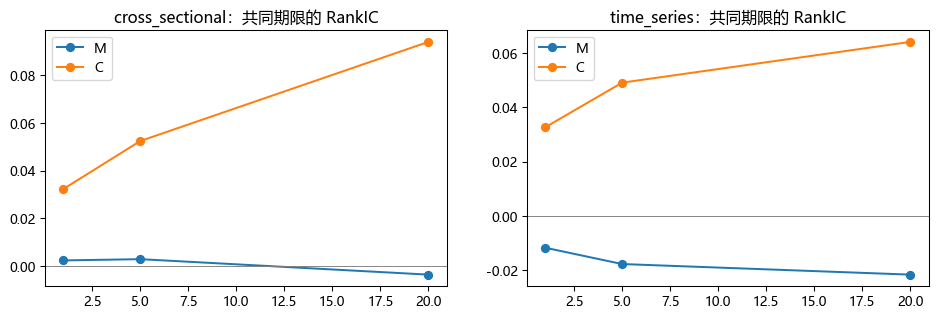

In [8]:
from factors.evaluation.ic import ic_details
from factors.evaluation.coverage import coverage_stats
from factors.evaluation.grouped import grouped_details
from factors.evaluation.regression import regression_details
from factors.evaluation.hit import hit_rate_details
from research.io import save_evaluation_result

prediction_results, ic_rows, ic_series = {}, [], {}
for name in ['M','C']:
    factor = to_long(reference_signals[name], 'factor')
    for h in PROTOCOL['horizons']:
        frame = pd.concat([factor, labels[f'fwd_{h}'].rename('label'), to_long(common_eligible, 'universe')], axis=1)
        frame = frame.loc[(frame.index.get_level_values('timestamp').year >= PROTOCOL['first_test_year'])]
        for mode, minimum in [('cross_sectional',10), ('time_series',126)]:
            result = ic_details(frame, mode, h, minimum, PROTOCOL['annualization'],
                nan_policy='drop', nw_max_lags=20, bs_seed=PROTOCOL['bootstrap']['seed'], bs_reps=500)
            prediction_results[(name,h,mode)] = result
            ic_series[(name,h,mode)] = result[1].ic
            ic_rows.append({'factor':name,'horizon':h,'mode':mode,'pearson_mean':result[0].ic.mean(),
                            'rank_mean':result[1].ic.mean(),'valid_groups':result[1].ic.notna().sum()})
            save_evaluation_result(result, EVAL_ROOT/f'{name}_{h}_{mode}',
                config={'name':name,'horizon':h,'mode':mode,'minimum':minimum,'nw_max_lags':20},
                metadata={'protocol':PROTOCOL_ID,'input':DATA_ID,'interpretation':'开发期内部样本外诊断'})
ic_table = pd.DataFrame(ic_rows)
display(ic_table.round(4))
ic_table.to_parquet(RUN_ROOT/'ic_summary.parquet', index=False)
fig, axes = plt.subplots(1,2,figsize=(12,3.5))
for mode, axis in zip(['cross_sectional','time_series'], axes):
    subset=ic_table.loc[ic_table['mode'].eq(mode)]
    for name in ['M','C']:
        rows=subset.loc[subset.factor.eq(name)]
        axis.plot(rows.horizon, rows.rank_mean, marker='o', label=name)
    axis.axhline(0,color='grey',lw=0.7); axis.set_title(mode+'：共同期限的 RankIC'); axis.legend()
plt.show()


**M 时序回归，控制变量数 0：** 分品种 HAC 与 pooled 详细结果已导出。

,分品种系数汇总
n_valid,64.000000
mean,0.000017
median,0.000062
std,0.002812
positive_ratio,0.531250


,fixed_effects,estimate,standard_error,t_stat,pvalue,observations
0,product,0.00063,0.00041,1.52898,0.13084,90327
1,product+timestamp,0.00036,0.00033,1.08296,0.28260,90327


,分品种系数
count,64.000000
mean,0.000017
std,0.002812
min,-0.007454
25%,-0.001459
50%,0.000062
75%,0.001799
max,0.005248


**M 时序回归，控制变量数 1：** 分品种 HAC 与 pooled 详细结果已导出。

,分品种系数汇总
n_valid,64.000000
mean,-0.000098
median,0.000020
std,0.002843
positive_ratio,0.500000


... (11 outputs left out)

,分品种系数
count,64.000000
mean,0.000464
std,0.007986
min,-0.038159
25%,-0.000723
50%,0.001184
75%,0.003299
max,0.024849


**C 方向命中率与基准：** 命中率应与偶然一致概率一起解释。

,threshold,term,mean,median,std,n_valid
1,0.0,chance_hit_rate,0.509242,0.500562,0.028172,64
4,0.0,excess_hit_rate,0.008817,0.006345,0.030205,64
5,0.0,hit_rate,0.518059,0.517903,0.036562,64
6,0.0,kappa,0.017177,0.013187,0.061456,64
19,0.5,chance_hit_rate,0.519104,0.505172,0.032846,49
22,0.5,excess_hit_rate,0.017421,0.015672,0.035338,49
23,0.5,hit_rate,0.536526,0.531993,0.047596,49
24,0.5,kappa,0.036209,0.031315,0.072843,49
37,1.0,chance_hit_rate,0.512970,0.506246,0.020776,32
40,1.0,excess_hit_rate,0.007251,0.001537,0.041781,32


,factor,mode,controls,estimate,standard_error,t_stat,pvalue,valid_units
0,M,cross_sectional,0,0.000526,0.000392,1.344140,0.178997,3239
1,M,cross_sectional,1,0.000413,0.000384,1.075063,0.282427,3239
2,C,cross_sectional,0,0.001254,0.000391,3.205683,0.001361,3239
3,C,cross_sectional,1,0.001216,0.000384,3.167020,0.001554,3239


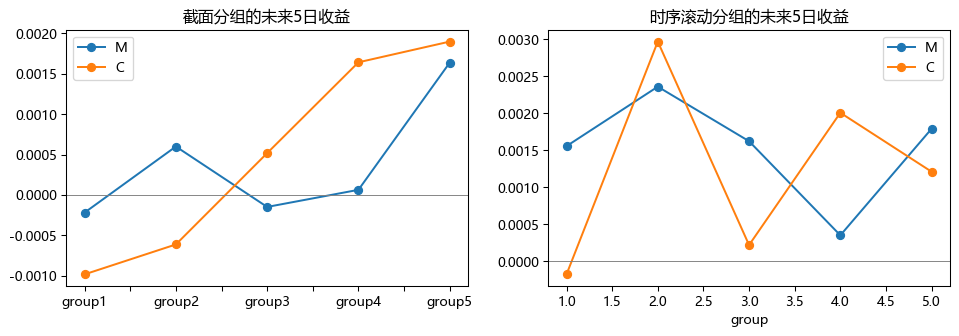

,factor,horizon,risk_normalized_rank_ic
0,M,5,-0.01399
1,C,5,0.04764


In [9]:
# 主要期限的分组、命中率、单因子与条件回归。未来标签的完整性仅用于评价，不反馈交易资格。
h = PROTOCOL['primary_horizon']
primary_frames, grouped_results, regression_rows = {}, {}, []
for name, other in [('M','C'),('C','M')]:
    frame = pd.concat([to_long(reference_signals[name],'factor'), to_long(reference_signals[other],'control'),
                       labels[f'fwd_{h}'].rename('label'),to_long(common_eligible,'universe')],axis=1)
    frame = frame.loc[frame.index.get_level_values('timestamp').year >= PROTOCOL['first_test_year']]
    primary_frames[name] = frame
    coverage_result = coverage_stats(frame)
    save_evaluation_result(coverage_result,EVAL_ROOT/f'{name}_coverage',config={'horizon':h})
    for mode, minimum in [('cross_sectional',10),('time_series',126)]:
        # 先约束共同完整行，使单因子和条件回归使用相同的可评价样本。
        matched = frame.loc[frame[['factor','control','label']].notna().all(axis=1)].copy()
        for controls in [(),('control',)]:
            reg = regression_details(matched,mode,h,minimum,nan_policy='drop',control_columns=controls,nw_max_lags=20)
            save_evaluation_result(reg,EVAL_ROOT/f'{name}_{mode}_controls{len(controls)}',config={'horizon':h,'controls':controls,'nw_max_lags':20})
            if mode=='cross_sectional':
                test=reg.factor_beta_mean_test
                regression_rows.append({'factor':name,'mode':mode,'controls':len(controls),
                    'estimate':test.estimate if test else np.nan,'standard_error':test.standard_error if test else np.nan,'t_stat':test.t_stat if test else np.nan,'pvalue':test.p_value if test else np.nan,
                    'valid_units':reg.factor_beta_summary.n_valid})
            else:
                display(Markdown(f'**{name} 时序回归，控制变量数 {len(controls)}：** 分品种 HAC 与 pooled 详细结果已导出。'))
                display(pd.Series(reg.factor_beta_summary.__dict__).to_frame('分品种系数汇总'))
                pooled=[]
                for effect,test in [('product',reg.pooled_product_fe),('product+timestamp',reg.pooled_product_timestamp_fe)]:
                    pooled.append({'fixed_effects':effect,'estimate':test.estimate,'standard_error':test.standard_error,
                                   't_stat':test.t_stat,'pvalue':test.p_value,'observations':test.n_observations})
                display(pd.DataFrame(pooled).round(5))
                display(pd.Series({product:test.estimate for product,test in reg.per_product_results.items()},name='分品种系数').describe().to_frame())
        # 同语义的研究端加速已与现有 grouped_details 在含缺失、并列及常数窗口上对照。
        from research.experiments.single_to_two_factor.diagnostics import rolling_time_series_groups
        group = (rolling_time_series_groups(frame,window=252,minimum=minimum,n_groups=5)
                 if mode=='time_series' else grouped_details(mode,frame,5,minimum,nan_policy='drop'))
        grouped_results[(name,mode)] = group
        save_evaluation_result(group,EVAL_ROOT/f'{name}_{mode}_groups',config={'horizon':h,'groups':5,'ts_window':252})
    hit=hit_rate_details(frame,h,126,'drop',(0.0,0.5,1.0))
    save_evaluation_result(hit,EVAL_ROOT/f'{name}_hit',config={'horizon':h,'thresholds':[0,0.5,1]})
    display(Markdown(f'**{name} 方向命中率与基准：** 命中率应与偶然一致概率一起解释。'))
    display(hit.summary.reset_index().loc[lambda x:x.term.isin(['hit_rate','chance_hit_rate','excess_hit_rate','kappa'])])
regression_table=pd.DataFrame(regression_rows)
display(regression_table)
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for name in ['M','C']:
    grouped_results[(name,'cross_sectional')].grouped_forward_returns.mean().plot(marker='o',ax=axes[0],label=name)
    pd.DataFrame(grouped_results[(name,'time_series')].grouped_forward_returns).mean(axis=1).plot(marker='o',ax=axes[1],label=name)
for axis,title in zip(axes,['截面分组的未来5日收益','时序滚动分组的未来5日收益']):
    axis.set_title(title);axis.axhline(0,color='grey',lw=0.7);axis.legend()
plt.show()

# 时序风险归一标签只改变评价目标，不改变预测期限或主实验信号。
risk_normalized_rows=[]
for name in ['M','C']:
    normalized = label_matrices[h]/(volatility*np.sqrt(h))
    frame=primary_frames[name].copy()
    frame['label']=to_long(normalized,'label').reindex(frame.index)
    result=ic_details(frame,'time_series',h,126,PROTOCOL['annualization'])
    save_evaluation_result(result,EVAL_ROOT/f'{name}_risk_normalized',config={'horizon':h,'volatility_window':60})
    risk_normalized_rows.append({'factor':name,'horizon':h,'risk_normalized_rank_ic':result[1].ic.mean()})
display(pd.DataFrame(risk_normalized_rows))


## 6．从预测变量到实际研究持仓

本节首次展示组合收益。M、C、S 的输入矩阵在两种 profile 下相同，改变的是信号映射、风险缩放和约束。目标波动率会影响 gross、净敞口与成本，因此不能用 CAGR 大小直接判断哪个 profile 更好。

先按全局相位运行，再将实际持仓送入公开记账组件。阶段间不拼接单独重启的年度净值；所有内部测试年份一次连续运行。

实际遵循现有状态机：计划调仓时构建净名义敞口为零的截面组合；非调仓日只将退出品种归零，其余冻结，因此净敞口与 gross 可能暂时偏离目标。风险审计报告实际暴露，不能把 profile 名称当作每天满足硬约束的证明。


CS_M 完成；Sharpe= 0.369


CS_C 完成；Sharpe= 1.13


CS_S 完成；Sharpe= 0.881


TS_M 完成；Sharpe= 0.672


TS_C 完成；Sharpe= 1.21


TS_S 完成；Sharpe= 1.071


,total_return,annualized_arithmetic_return,cagr,annualized_volatility,sharpe,max_drawdown,n_periods,mean_turnover,mean_gross,max_product_weight,warning_count
name,,,,,,,,,,,
CS_M,0.3479,0.0243,0.0224,0.0658,0.3689,-0.1640,3401.0,0.1735,0.8930,0.18,0
CS_C,1.3195,0.0639,0.0643,0.0566,1.1302,-0.1001,3401.0,0.1339,0.8940,0.18,0
CS_S,1.0336,0.0545,0.0540,0.0619,0.8807,-0.1076,3401.0,0.1520,0.8943,0.18,0
TS_M,1.4345,0.0716,0.0681,0.1066,0.6716,-0.2489,3401.0,0.2441,1.2240,0.20,0
TS_C,3.3156,0.1127,0.1144,0.0932,1.2099,-0.1490,3401.0,0.1883,1.2779,0.20,0
TS_S,3.2986,0.1137,0.1141,0.1062,1.0709,-0.2665,3401.0,0.2375,1.3331,0.20,0


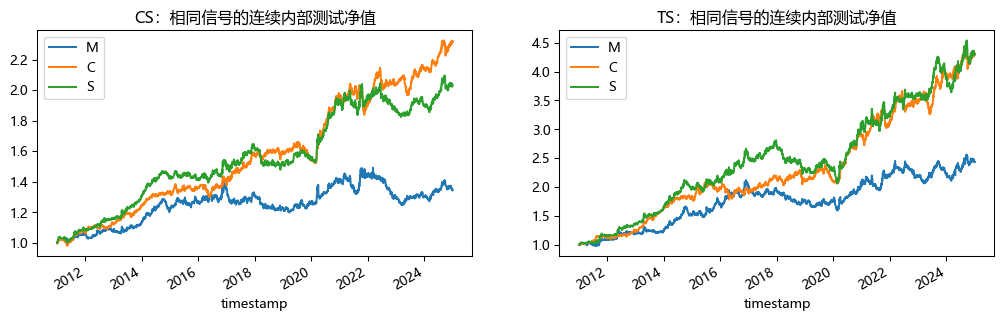

In [10]:
base_constraint = ConstraintConfig(max_product_weight=PROTOCOL['max_product_weight'])
SPECS = {
    'CS': DiagnosticPortfolioSpec(name='shared_CS', harvest_profile=market_rank_ls,
        rebalance=RebalanceConfig(PROTOCOL['interval']), constraint=base_constraint,
        cost=CostConfig(PROTOCOL['cost_rate']), min_cross_section_size=PROTOCOL['min_products'],
        annualization_factor=PROTOCOL['annualization'],missing_return_policy=PROTOCOL['missing_return_policy']),
    'TS': DiagnosticPortfolioSpec(name='shared_TS', harvest_profile=ts_inv_vol_target_vol,
        rebalance=RebalanceConfig(PROTOCOL['interval']),
        constraint=ConstraintConfig(max_product_weight=PROTOCOL['max_product_weight'],max_gross=PROTOCOL['max_gross'],max_volatility_scaler=PROTOCOL['max_volatility_scaler']),
        risk=RiskConfig(**PROTOCOL['risk']),clip_bound=PROTOCOL['clip'],cost=CostConfig(PROTOCOL['cost_rate']),
        annualization_factor=PROTOCOL['annualization'],missing_return_policy=PROTOCOL['missing_return_policy']),
}
TEST_START, TEST_END = f"{PROTOCOL['first_test_year']}-01-01", PROTOCOL['end_date']
runs, results = {}, {}
for profile,spec in SPECS.items():
    for name,signal in reference_signals.items():
        key=f'{profile}_{name}'
        run=simulate_signal(panel,signal,spec,TEST_START,TEST_END,audit=True)
        result=evaluate_target_weights(panel,run,spec,name=key,metadata={'protocol':PROTOCOL_ID,'input':DATA_ID,'code':CODE_ID,'stage':'fixed'})
        runs[key],results[key]=run,result
        print(key,'完成；Sharpe=',round(result.performance.loc['proxy_net','sharpe'],3),flush=True)

def summary_table(result_dict):
    rows=[]
    for name,result in result_dict.items():
        row=result.performance.loc['proxy_net'].to_dict()
        row.update(name=name,mean_turnover=result.turnover.mean(),mean_gross=result.exposures.gross_exposure.mean(),
                   max_product_weight=result.target_weights.abs().max(),warning_count=len(result.warnings))
        rows.append(row)
    return pd.DataFrame(rows).set_index('name')

display(summary_table(results).round(4))
fig,axes=plt.subplots(1,2,figsize=(13,3.5))
for profile,axis in zip(SPECS,axes):
    for name in reference_signals:
        results[f'{profile}_{name}'].nav.proxy_net_nav.plot(ax=axis,label=name)
    axis.set_title(profile+'：相同信号的连续内部测试净值');axis.legend()
plt.show()


## 7．互补性：四种相关性与共同亏损

因子相关性低不等于策略收益相关性低；单因子显著也不等于加入组合有价值。下面分别观察评分、预测能力、持仓与收益。条件回归仅检验线性增量关系，不能代替成本后的组合评价。


,profile,signal_rank_corr,ic_series_corr,mean_position_corr,return_corr,both_negative_fraction
0,CS,0.0327,0.0304,0.0295,0.0186,0.2264
1,TS,0.0327,-0.1099,-0.0161,-0.0626,0.2088


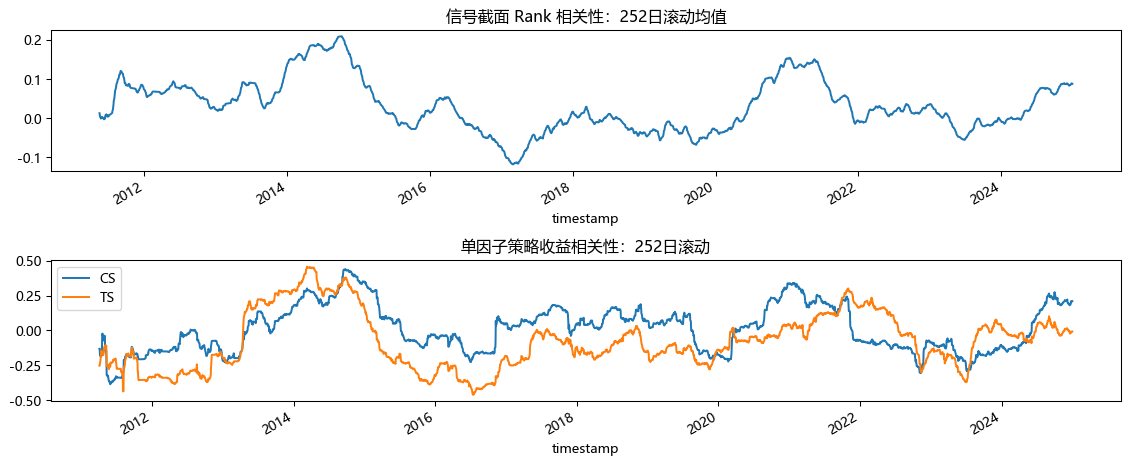

In [11]:
shared_pair=pd.concat([to_long(reference_signals['M'],'M'),to_long(reference_signals['C'],'C')],axis=1).dropna()
signal_correlation=shared_pair.groupby(level='timestamp').apply(lambda x:x.M.corr(x.C,method='spearman'))
relation_rows=[]
for profile in SPECS:
    m,c=results[f'{profile}_M'],results[f'{profile}_C']
    wm,wc=runs[f'{profile}_M'].weights,runs[f'{profile}_C'].weights
    daily_position_corr=wm.corrwith(wc,axis=1)
    mode='cross_sectional' if profile=='CS' else 'time_series'
    m_ic,c_ic=ic_series[('M',PROTOCOL['primary_horizon'],mode)],ic_series[('C',PROTOCOL['primary_horizon'],mode)]
    returns_pair=pd.concat([m.portfolio_returns.proxy_net_return.rename('M'),c.portfolio_returns.proxy_net_return.rename('C')],axis=1)
    relation_rows.append({'profile':profile,'signal_rank_corr':signal_correlation.mean(),'ic_series_corr':m_ic.corr(c_ic),
        'mean_position_corr':daily_position_corr.mean(),'return_corr':returns_pair.M.corr(returns_pair.C),
        'both_negative_fraction':((returns_pair.M<0)&(returns_pair.C<0)).mean()})
relations=pd.DataFrame(relation_rows)
display(relations.round(4))
fig,axes=plt.subplots(2,1,figsize=(12,5))
signal_correlation.rolling(252,min_periods=60).mean().plot(ax=axes[0],title='信号截面 Rank 相关性：252日滚动均值')
for profile in SPECS:
    m=results[f'{profile}_M'].portfolio_returns.proxy_net_return
    c=results[f'{profile}_C'].portfolio_returns.proxy_net_return
    m.rolling(252,min_periods=60).corr(c).plot(ax=axes[1],label=profile)
axes[1].set_title('单因子策略收益相关性：252日滚动');axes[1].legend();plt.tight_layout();plt.show()
relations.to_parquet(RUN_ROOT/'relations.parquet',index=False)


## 8．两种组合路径：信号合成与持仓合成

S 先合并评分，再由 profile 形成持仓。P 先由 profile 各自形成持仓，再合并并执行组合级风险处理。排名、clip 和风险约束使两者一般不相等。

持仓组合保留原始混合头寸，先抵消同品种相反方向，再计算最终头寸换手与成本。时序叠加仅计算组合风险，不再次逆波动率；截面叠加保持多空两侧共同可达敞口。未缩放的混合 gross 用于理解自然分散，不能直接与最终目标风险组合混为一谈。


,total_return,annualized_arithmetic_return,cagr,annualized_volatility,sharpe,max_drawdown,n_periods,mean_turnover,mean_gross,max_product_weight,warning_count
name,,,,,,,,,,,
CS_M,0.3479,0.0243,0.0224,0.0658,0.3689,-0.1640,3401.0,0.1735,0.8930,0.18,0
CS_C,1.3195,0.0639,0.0643,0.0566,1.1302,-0.1001,3401.0,0.1339,0.8940,0.18,0
CS_S,1.0336,0.0545,0.0540,0.0619,0.8807,-0.1076,3401.0,0.1520,0.8943,0.18,0
TS_M,1.4345,0.0716,0.0681,0.1066,0.6716,-0.2489,3401.0,0.2441,1.2240,0.20,0
TS_C,3.3156,0.1127,0.1144,0.0932,1.2099,-0.1490,3401.0,0.1883,1.2779,0.20,0
TS_S,3.2986,0.1137,0.1141,0.1062,1.0709,-0.2665,3401.0,0.2375,1.3331,0.20,0
CS_P,1.2550,0.0624,0.0621,0.0648,0.9625,-0.1323,3401.0,0.1601,0.8943,0.20,0
TS_P,4.2824,0.1286,0.1313,0.1026,1.2531,-0.1999,3401.0,0.2581,1.4831,0.20,0


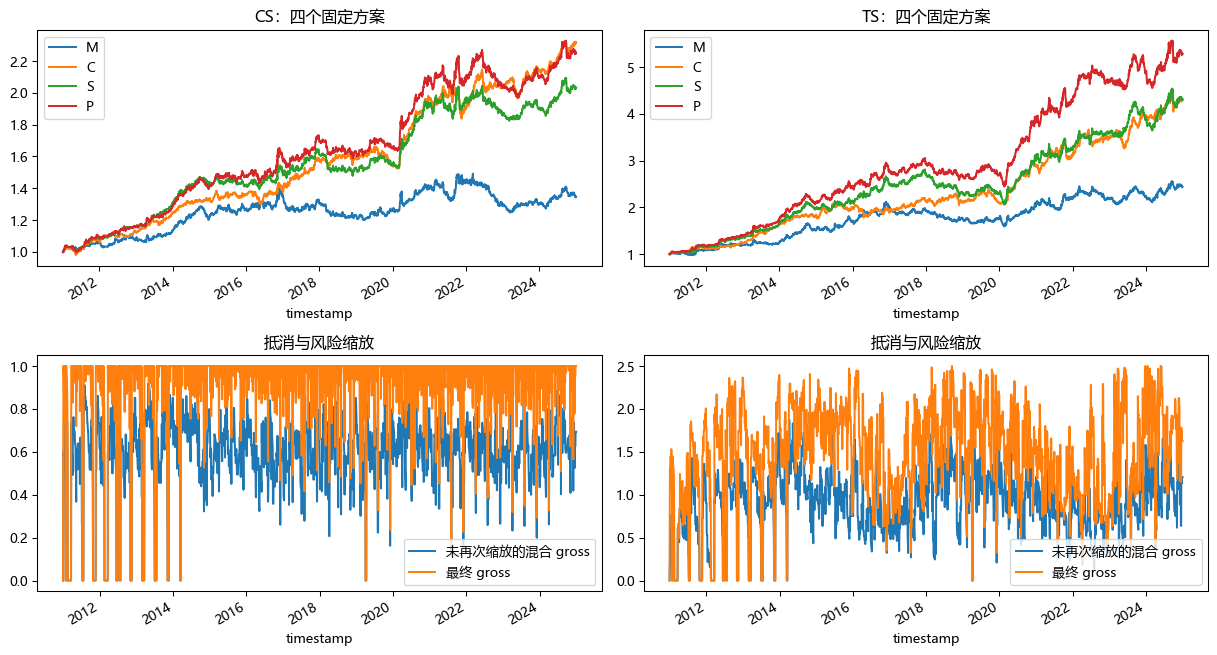

In [12]:
for profile,spec in SPECS.items():
    key=f'{profile}_P'
    run=combine_positions(panel,runs[f'{profile}_M'],runs[f'{profile}_C'],PROTOCOL['reference_alpha'],spec,audit=True)
    result=evaluate_target_weights(panel,run,spec,name=key,metadata={'protocol':PROTOCOL_ID,'input':DATA_ID,'stage':'fixed_positions','alpha':0.5})
    runs[key],results[key]=run,result
fixed_summary=summary_table(results)
display(fixed_summary.round(4))
fixed_summary.to_parquet(RUN_ROOT/'fixed_summary.parquet')
fig,axes=plt.subplots(2,2,figsize=(13,7))
for j,profile in enumerate(SPECS):
    for name in ['M','C','S','P']:
        results[f'{profile}_{name}'].nav.proxy_net_nav.plot(ax=axes[0,j],label=name)
    axes[0,j].set_title(profile+'：四个固定方案');axes[0,j].legend()
    raw_gross=runs[f'{profile}_P'].raw_mix.abs().sum(axis=1)
    raw_gross.plot(ax=axes[1,j],label='未再次缩放的混合 gross')
    results[f'{profile}_P'].exposures.gross_exposure.plot(ax=axes[1,j],label='最终 gross')
    axes[1,j].set_title('抵消与风险缩放');axes[1,j].legend()
plt.tight_layout();plt.show()
# 保存实际输入和实际权重；所有快照支持独立记账重放。
for name,result in results.items():
    save_result(RUN_ROOT/'fixed'/name,result,panel,runs[name],{'protocol':PROTOCOL_ID,'input':DATA_ID,'code':CODE_ID,'stage':'fixed'})


## 9．截面专用预处理的独立对照

主实验没有改变两种 profile 的输入。这里仅对固定参考的截面实验改为当日 z-score，检验适配处理本身的影响。单因子排序在正比例／平移变换下通常不变，但 clip 产生并列、合成时的相对尺度和缺失处理都可能改变持仓。


,total_return,annualized_arithmetic_return,cagr,annualized_volatility,sharpe,max_drawdown,n_periods,mean_turnover,mean_gross,max_product_weight,warning_count
name,,,,,,,,,,,
CS_M,0.3479,0.0243,0.0224,0.0658,0.3689,-0.1640,3401.0,0.1735,0.8930,0.18,0
CS_C,1.3195,0.0639,0.0643,0.0566,1.1302,-0.1001,3401.0,0.1339,0.8940,0.18,0
CS_S,1.0336,0.0545,0.0540,0.0619,0.8807,-0.1076,3401.0,0.1520,0.8943,0.18,0
CS_zscore_M,0.3423,0.0240,0.0221,0.0660,0.3637,-0.1639,3401.0,0.1734,0.8930,0.18,0
CS_zscore_C,1.3231,0.0641,0.0644,0.0566,1.1310,-0.1003,3401.0,0.1339,0.8940,0.18,0
CS_zscore_S,0.9949,0.0531,0.0525,0.0619,0.8579,-0.1119,3401.0,0.1551,0.8941,0.18,0


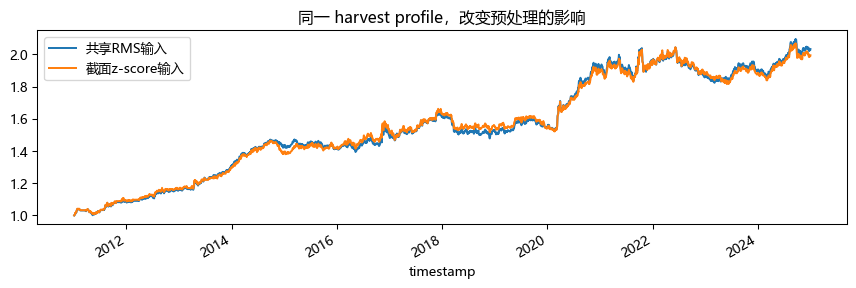

In [13]:
adapted_signals={}
for name,key in [('M',M_REF),('C',C_REF)]:
    values=CrossSectionalZscore().transform(to_long(raw_factors[key],'factor'),to_long(common_eligible,'eligible')).values
    adapted_signals[name]=values.unstack('product').reindex_like(raw_returns).clip(-PROTOCOL['clip'],PROTOCOL['clip']).where(new_entry_allowed,axis=0)
adapted_signals['S']=0.5*adapted_signals['M']+0.5*adapted_signals['C']
adaptation={}
for name,signal in adapted_signals.items():
    run=simulate_signal(panel,signal,SPECS['CS'],TEST_START,TEST_END)
    adaptation[f'CS_zscore_{name}']=evaluate_target_weights(panel,run,SPECS['CS'],name=f'CS_zscore_{name}')
display(pd.concat([fixed_summary.loc[['CS_M','CS_C','CS_S']],summary_table(adaptation)]).round(4))
fig,axis=plt.subplots(figsize=(11,3))
results['CS_S'].nav.proxy_net_nav.plot(ax=axis,label='共享RMS输入')
adaptation['CS_zscore_S'].nav.proxy_net_nav.plot(ax=axis,label='截面z-score输入')
axis.set_title('同一 harvest profile，改变预处理的影响');axis.legend();plt.show()


## 10．有限选择：研究规则本身也要接受时间验证

每条线路独立选择 3 个 M、3 个 C、27 个 S、27 个 P。验证期净 Sharpe 为唯一排序主指标；并列时依次选择换手较低、距离参考规格较近、稳定编号较小的候选。风险参数、成本、调仓频率和方向不择优。

2011 年：训练 2005—2009、验证 2010、测试 2011；以后每年滚动。候选验证只拟合训练期 RMS；选定后与固定参考一样，用训练＋验证重新拟合尺度。标签检验按真实成熟日限制；候选选择使用的是截至验证结束已实现的组合日收益，没有借用之后的前瞻标签。

每个候选成对评价两个 profile；自适应结果允许选中不同参数，故不能再把它们的差异完全解释为持仓映射差异。跨年保持风险历史和旧持仓，直到下一个全局计划调仓日才切换。

本例的训练拟合仅估计因子尺度，不训练监督式收益预测模型；验证排序使用当时已经实现的组合日收益。`label_end` 记录标签成熟日期，后续扩展到 IC 权重或监督模型时，必须进一步按训练截止时点筛选成熟标签。


In [14]:
# 候选选择与并列规则直接定义在 notebook；辅助区不维护另一份选择策略。
def choose_candidate(table, *, min_observations, tolerance):
    """预设并列顺序：Sharpe、换手、距参考距离、稳定编号。"""
    good = table.loc[(table.status == 'ok') & (table.n_observations >= min_observations) & np.isfinite(table.sharpe)]
    if good.empty:
        raise ValueError('没有可选择的候选；禁止静默回退。')
    tied = good.loc[good.sharpe >= good.sharpe.max()-tolerance]
    tied = tied.loc[tied.turnover <= tied.turnover.min()+tolerance]
    return tied.sort_values(['reference_distance', 'candidate_id']).iloc[0]

# 候选与并列距离定义留在 notebook，禁止辅助模块暗藏参数搜索。
candidate_rows=[]
m_keys=[f'M_{window:03}' for window in PROTOCOL['momentum_windows']]
c_keys=['C_%03d_%03d'%tuple(band) for band in PROTOCOL['carry_bands']]
for i,key in enumerate(m_keys):
    candidate_rows.append(dict(candidate_id=key,path='M',momentum=key,carry='',alpha=np.nan,reference_distance=abs(i-m_keys.index(M_REF))))
for i,key in enumerate(c_keys):
    candidate_rows.append(dict(candidate_id=key,path='C',momentum='',carry=key,alpha=np.nan,reference_distance=abs(i-c_keys.index(C_REF))))
for path_name in ['S','P']:
    for m,c,alpha in itertools.product(m_keys,c_keys,PROTOCOL['alphas']):
        distance=abs(m_keys.index(m)-m_keys.index(M_REF))+abs(c_keys.index(c)-c_keys.index(C_REF))+2*abs(alpha-0.5)
        candidate_rows.append(dict(candidate_id=f'{path_name}_{m}_{c}_a{int(alpha*100):03}',path=path_name,momentum=m,carry=c,alpha=alpha,reference_distance=distance))
candidates=pd.DataFrame(candidate_rows)
assert len(candidates)==60 and candidates.candidate_id.is_unique
candidates.to_parquet(RUN_ROOT/'candidates.parquet',index=False)
display(candidates.groupby('path').size().rename('每条线路候选数').to_frame())
fold_rows, validation_tables, selection_rows=[] , [], []
for year in range(PROTOCOL['first_test_year'],PROTOCOL['last_test_year']+1):
    train_start,train_end=f'{year-6}-01-01',f'{year-2}-12-31'
    val_start,val_end=f'{year-1}-01-01',f'{year-1}-12-31'
    fit_signals,fit_states=fit_shared_signals(train_start,train_end)
    (RUN_ROOT/'validation_scaling').mkdir(parents=True,exist_ok=True)
    fit_states.to_parquet(RUN_ROOT/'validation_scaling'/f'{year}.parquet',index=False)
    fold_rows.append(dict(test_year=year,train_start=train_start,train_end=train_end,validation_start=val_start,
                          validation_end=val_end,test_start=f'{year}-01-01',test_end=f'{year}-12-31'))
    table=validation_candidates(panel,fit_signals,candidates,SPECS,val_start,val_end,
        cache_dir=RUN_ROOT/'checkpoints',identity=RUN_ID)
    table['test_year']=year
    validation_tables.append(table)
    for profile in SPECS:
        for path_name in ['M','C','S','P']:
            selected=choose_candidate(table.loc[table.profile.eq(profile)&table.path.eq(path_name)],
                min_observations=PROTOCOL['min_validation_observations'],tolerance=PROTOCOL['tie_tolerance']).to_dict()
            selected['test_year']=year
            selection_rows.append(selected)
folds=pd.DataFrame(fold_rows)
validation_table=pd.concat(validation_tables,ignore_index=True)
selections=pd.DataFrame(selection_rows)
folds.to_parquet(RUN_ROOT/'folds.parquet',index=False)
validation_table.to_parquet(RUN_ROOT/'validation_all_candidates.parquet',index=False)
selections.to_parquet(RUN_ROOT/'selections.parquet',index=False)
assert (pd.to_datetime(selections.selection_cutoff).dt.year < selections.test_year).all()
display(folds)
display(selections[['test_year','profile','path','candidate_id','sharpe','turnover','selection_cutoff']])
print('验证失败／无定义候选：',int(validation_table.status.ne('ok').sum()))


,每条线路候选数
path,
C,3
M,3
P,27
S,27


验证 2010 / CS: 60 个候选，2.1s。


验证 2010 / TS: 60 个候选，4.4s。


验证 2011 / CS: 60 个候选，2.2s。


验证 2011 / TS: 60 个候选，4.3s。


验证 2012 / CS: 60 个候选，2.3s。


... (22 outputs left out)

验证 2023 / TS: 60 个候选，5.2s。


,test_year,train_start,train_end,validation_start,validation_end,test_start,test_end
0,2011,2005-01-01,2009-12-31,2010-01-01,2010-12-31,2011-01-01,2011-12-31
1,2012,2006-01-01,2010-12-31,2011-01-01,2011-12-31,2012-01-01,2012-12-31
2,2013,2007-01-01,2011-12-31,2012-01-01,2012-12-31,2013-01-01,2013-12-31
3,2014,2008-01-01,2012-12-31,2013-01-01,2013-12-31,2014-01-01,2014-12-31
4,2015,2009-01-01,2013-12-31,2014-01-01,2014-12-31,2015-01-01,2015-12-31
5,2016,2010-01-01,2014-12-31,2015-01-01,2015-12-31,2016-01-01,2016-12-31
6,2017,2011-01-01,2015-12-31,2016-01-01,2016-12-31,2017-01-01,2017-12-31
7,2018,2012-01-01,2016-12-31,2017-01-01,2017-12-31,2018-01-01,2018-12-31
8,2019,2013-01-01,2017-12-31,2018-01-01,2018-12-31,2019-01-01,2019-12-31
9,2020,2014-01-01,2018-12-31,2019-01-01,2019-12-31,2020-01-01,2020-12-31


,test_year,profile,path,candidate_id,sharpe,turnover,selection_cutoff
0,2011,CS,M,M_060,0.258018,0.113504,2010-12-31
1,2011,CS,C,C_000_365,2.510502,0.112433,2010-12-31
2,2011,CS,S,S_M_060_C_000_365_a025,1.596643,0.103478,2010-12-31
3,2011,CS,P,P_M_060_C_000_365_a025,2.132766,0.107894,2010-12-31
4,2011,TS,M,M_060,0.855338,0.115590,2010-12-31
...,...,...,...,...,...,...,...
107,2024,CS,P,P_M_020_C_014_365_a025,0.789759,0.144231,2023-12-31
108,2024,TS,M,M_010,0.707220,0.340064,2023-12-31
109,2024,TS,C,C_014_365,1.387326,0.178270,2023-12-31
110,2024,TS,S,S_M_010_C_014_365_a050,0.998966,0.323534,2023-12-31


验证失败／无定义候选： 0


,total_return,annualized_arithmetic_return,cagr,annualized_volatility,sharpe,max_drawdown,n_periods,mean_turnover,mean_gross,max_product_weight,warning_count
name,,,,,,,,,,,
CS_M_adaptive,0.4478,0.0296,0.0278,0.0656,0.4506,-0.1445,3401.0,0.1713,0.8940,0.18,0
CS_C_adaptive,1.2221,0.0607,0.0609,0.0558,1.0888,-0.1015,3401.0,0.1345,0.8940,0.18,0
CS_S_adaptive,0.7013,0.0413,0.0402,0.0617,0.6693,-0.1216,3401.0,0.1598,0.8948,0.18,0
CS_P_adaptive,0.9096,0.0498,0.0491,0.0616,0.8093,-0.1389,3401.0,0.1608,0.8941,0.20,0
TS_M_adaptive,0.9865,0.0563,0.0522,0.1046,0.5383,-0.2189,3401.0,0.2377,1.2031,0.20,0
TS_C_adaptive,2.9636,0.1063,0.1074,0.0924,1.1509,-0.1582,3401.0,0.1905,1.2793,0.20,0
TS_S_adaptive,2.3258,0.0941,0.0931,0.1003,0.9380,-0.2584,3401.0,0.2328,1.2990,0.20,0
TS_P_adaptive,3.1935,0.1112,0.1121,0.0996,1.1161,-0.2216,3401.0,0.2373,1.4086,0.20,0


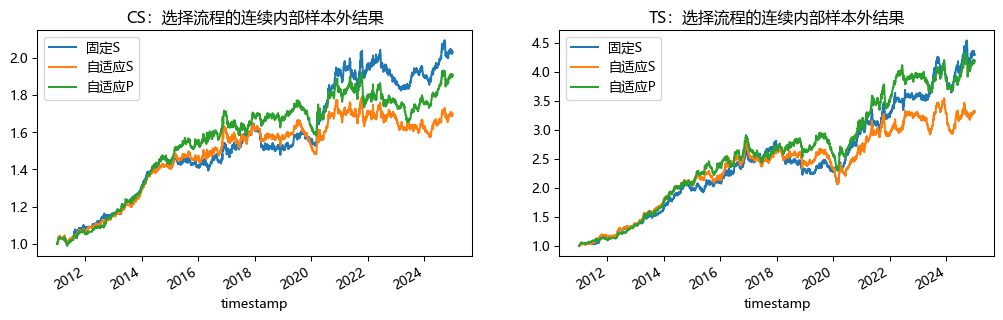

In [15]:
# 拼接的是决策输入而不是年度净值；状态机仅运行一次，切换成本自然进入账本。
adaptive_results, adaptive_runs={},{}
for profile,spec in SPECS.items():
    for path_name in ['M','C','S','P']:
        first=pd.DataFrame(np.nan,index=raw_returns.index,columns=raw_returns.columns)
        second=first.copy()
        alpha_tape=pd.Series(0.5,index=raw_returns.index)
        for year in range(PROTOCOL['first_test_year'],PROTOCOL['last_test_year']+1):
            choice=selections.loc[selections.profile.eq(profile)&selections.path.eq(path_name)&selections.test_year.eq(year)].iloc[0]
            rows=next_return_year.eq(year)
            pool=scaled_by_year[year]
            if path_name=='M':
                first.loc[rows]=pool[choice.momentum].loc[rows]
            elif path_name=='C':
                first.loc[rows]=pool[choice.carry].loc[rows]
            elif path_name=='S':
                first.loc[rows]=choice.alpha*pool[choice.momentum].loc[rows]+(1-choice.alpha)*pool[choice.carry].loc[rows]
            else:
                first.loc[rows]=pool[choice.momentum].loc[rows]
                second.loc[rows]=pool[choice.carry].loc[rows]
                alpha_tape.loc[rows]=choice.alpha
        run=simulate_signal(panel,first,spec,TEST_START,TEST_END,audit=True)
        if path_name=='P':
            other=simulate_signal(panel,second,spec,TEST_START,TEST_END)
            run=combine_positions(panel,run,other,alpha_tape,spec,audit=True)
        name=f'{profile}_{path_name}_adaptive'
        result=evaluate_target_weights(panel,run,spec,name=name,metadata={'protocol':PROTOCOL_ID,'input':DATA_ID,'stage':'adaptive'})
        adaptive_runs[name],adaptive_results[name]=run,result
        save_result(RUN_ROOT/'adaptive'/name,result,panel,run,{'protocol':PROTOCOL_ID,'input':DATA_ID,'code':CODE_ID,'stage':'adaptive'})
adaptive_summary=summary_table(adaptive_results)
display(adaptive_summary.round(4))
adaptive_summary.to_parquet(RUN_ROOT/'adaptive_summary.parquet')
fig,axes=plt.subplots(1,2,figsize=(13,3.5))
for profile,axis in zip(SPECS,axes):
    results[f'{profile}_S'].nav.proxy_net_nav.plot(ax=axis,label='固定S')
    adaptive_results[f'{profile}_S_adaptive'].nav.proxy_net_nav.plot(ax=axis,label='自适应S')
    adaptive_results[f'{profile}_P_adaptive'].nav.proxy_net_nav.plot(ax=axis,label='自适应P')
    axis.set_title(profile+'：选择流程的连续内部样本外结果');axis.legend()
plt.show()


## 11．增量证据、预设挑战与实施审计

主检验保持四项固定比较。共同日期块同时抽取全部策略，保留它们共同经历的市场冲击；四项区间各为 98.75%，家族级误差按 Bonferroni 处理。这不能修复此前所有历史探索的偏差。

置信区间跨零，表示当前证据不足；负向证据不能改写成“因子永远无用”。相对一个单因子有改善，也不代表同时改善另一个单因子。


In [16]:
fixed_returns=pd.concat({name:result.portfolio_returns.proxy_net_return for name,result in results.items()},axis=1)
assert not fixed_returns.isna().any().any()
comparisons=[(f'{profile}_S',f'{profile}_{base}') for profile in SPECS for base in ['M','C']]
primary_inference=paired_block_bootstrap(fixed_returns,comparisons,
    annualization=PROTOCOL['annualization'],**PROTOCOL['bootstrap'])
display(primary_inference.round(4))
primary_inference.to_parquet(RUN_ROOT/'primary_inference.parquet',index=False)
# 次级证据不代替主检验，也不把择优后的两个不同输入称为同参数比较。
secondary_rows=[]
for profile in SPECS:
    for name in ['M','C','S','P']:
        secondary_rows.append({'profile':profile,'path':name,'fixed_sharpe':fixed_summary.loc[f'{profile}_{name}','sharpe'],
            'adaptive_sharpe':adaptive_summary.loc[f'{profile}_{name}_adaptive','sharpe']})
display(pd.DataFrame(secondary_rows).round(4))
bootstrap_sensitivity=[]
for block in PROTOCOL['challenges']['bootstrap_blocks']:
    config={**PROTOCOL['bootstrap'],'block_size':block}
    bootstrap_sensitivity.append(paired_block_bootstrap(fixed_returns,comparisons,annualization=PROTOCOL['annualization'],**config))
bootstrap_sensitivity=pd.concat(bootstrap_sensitivity,ignore_index=True)
display(bootstrap_sensitivity[['new','base','block_size','delta_sharpe','ci_low','ci_high']].round(4))
bootstrap_sensitivity.to_parquet(RUN_ROOT/'bootstrap_sensitivity.parquet',index=False)


,new,base,delta_sharpe,ci_low,ci_high,annualized_mean_difference,...,confidence_level,family_size,block_size,reps,valid_reps,decision
0,CS_S,CS_M,0.5118,0.0251,0.9895,0.0302,...,0.9875,4,20,5000,5000,改善且达到教学幅度
1,CS_S,CS_C,-0.2494,-0.7950,0.2859,-0.0094,...,0.9875,4,20,5000,5000,证据不足或幅度较小
2,TS_S,TS_M,0.3993,-0.0404,0.8105,0.0421,...,0.9875,4,20,5000,5000,证据不足或幅度较小
3,TS_S,TS_C,-0.1389,-0.8036,0.5529,0.0010,...,0.9875,4,20,5000,5000,证据不足或幅度较小


,profile,path,fixed_sharpe,adaptive_sharpe
0,CS,M,0.3689,0.4506
1,CS,C,1.1302,1.0888
2,CS,S,0.8807,0.6693
3,CS,P,0.9625,0.8093
4,TS,M,0.6716,0.5383
5,TS,C,1.2099,1.1509
6,TS,S,1.0709,0.9380
7,TS,P,1.2531,1.1161


,new,base,block_size,delta_sharpe,ci_low,ci_high
0,CS_S,CS_M,5,0.5118,0.0274,1.0317
1,CS_S,CS_C,5,-0.2494,-0.8343,0.3057
2,TS_S,TS_M,5,0.3993,-0.0181,0.8210
3,TS_S,TS_C,5,-0.1389,-0.8326,0.6029
4,CS_S,CS_M,60,0.5118,0.0504,0.9733
5,CS_S,CS_C,60,-0.2494,-0.8134,0.2756
6,TS_S,TS_M,60,0.3993,-0.0187,0.8126
7,TS_S,TS_C,60,-0.1389,-0.8065,0.5244


cost_bps,0.0,0.3,1.0,3.0
name,,,,
CS_C,1.189,1.172,1.130,1.011
CS_M,0.435,0.415,0.369,0.236
CS_P,1.025,1.006,0.962,0.838
CS_S,0.942,0.924,0.881,0.757
TS_C,1.260,1.245,1.210,1.108
TS_M,0.729,0.712,0.672,0.556
TS_P,1.316,1.297,1.253,1.126
TS_S,1.127,1.110,1.071,0.958


period,2011-2015,2016-2020,2021-2024
name,,,
CS_C,1.473,1.276,0.707
CS_M,0.964,0.331,-0.106
CS_P,1.664,1.021,0.327
CS_S,1.533,0.975,0.246
TS_C,1.876,0.804,1.094
TS_M,1.171,0.406,0.443
TS_P,2.111,0.933,0.784
TS_S,1.711,0.727,0.828


sector,base_metals,chemicals,energy,ferroalloy,forest,furnace_burden,...,livestock,newenergy_metals,oilseeds_oils,precious_metals,softs,steel_products
CS_M,-0.1305,0.2282,-0.0812,-0.0075,0.0327,0.1744,...,-0.0115,0.0068,0.0939,-0.0014,0.0223,0.0717
CS_C,0.0690,0.1768,0.0251,-0.0455,-0.0045,0.2208,...,0.0061,0.0042,0.2425,-0.0114,0.0925,0.1023
CS_S,-0.0732,0.2342,-0.0447,-0.0279,0.0286,0.2870,...,-0.0209,0.0049,0.2200,-0.0022,0.0524,0.1276
TS_M,0.0600,0.3310,-0.0361,0.0377,0.0418,0.2204,...,-0.0203,0.0147,0.1094,0.0426,0.0421,0.2075
TS_C,0.1335,0.2941,0.0276,-0.0338,0.0174,0.2993,...,-0.0416,0.0148,0.4629,0.0071,0.1981,0.2108
TS_S,0.1137,0.3604,-0.0170,0.0067,0.0554,0.4234,...,-0.0591,0.0178,0.3084,0.0437,0.1369,0.2463
CS_P,-0.0336,0.2741,-0.0525,-0.0396,0.0195,0.2708,...,0.0003,0.0049,0.2624,-0.0149,0.0775,0.1096
TS_P,0.1522,0.4225,-0.0281,-0.0054,0.0348,0.4163,...,-0.0420,0.0229,0.4068,0.0292,0.1586,0.2411


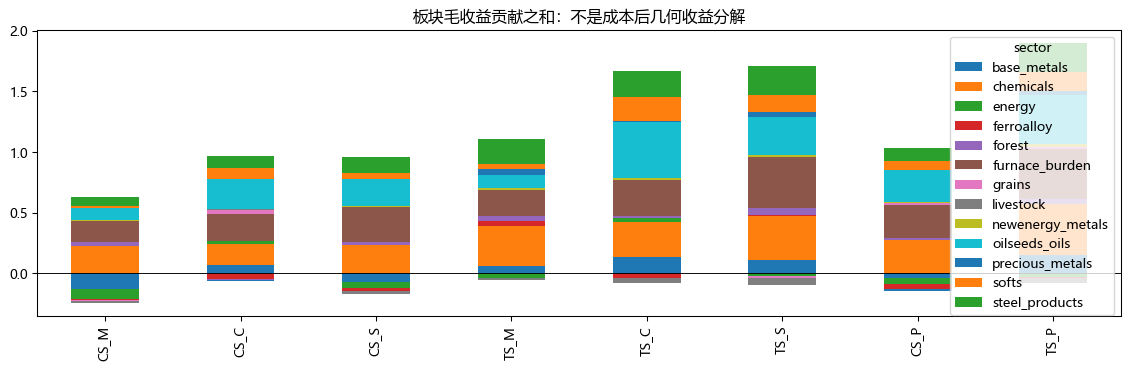

In [17]:
from factors.diagnostic_portfolio.accounting import compute_performance

def metrics_of_returns(values):
    # 这里 values 已经是待评价的净收益；计算口径继续复用项目组件。
    return compute_performance(values,values,None,PROTOCOL['annualization'])[0].loc['proxy_net'].to_dict()

cost_rows=[]
for name,result in results.items():
    gross=result.portfolio_returns.gross_return
    unit_turnover=pd.Series(result.turnover.to_numpy(),index=result.portfolio_returns.index)
    for bps in PROTOCOL['challenges']['cost_bps']:
        values=gross-unit_turnover*(bps/10000)
        cost_rows.append({'name':name,'cost_bps':bps,**metrics_of_returns(values)})
cost_table=pd.DataFrame(cost_rows)
display(cost_table.pivot(index='name',columns='cost_bps',values='sharpe').round(3))
cost_table.to_parquet(RUN_ROOT/'cost_sensitivity.parquet',index=False)

# 分时期和分板块是诊断，不在观察后选择表现好的市场。
period_rows=[]
for name,result in results.items():
    ret=result.portfolio_returns.proxy_net_return
    for low,high in [(2011,2015),(2016,2020),(2021,2024)]:
        values=ret.loc[f'{low}':f'{high}']
        period_rows.append({'name':name,'period':f'{low}-{high}',**metrics_of_returns(values)})
period_table=pd.DataFrame(period_rows)
display(period_table.pivot(index='name',columns='period',values='sharpe').round(3))
period_table.to_parquet(RUN_ROOT/'periods.parquet',index=False)
sector_rows=[]
for name,result in results.items():
    sector=result.sector_attribution.groupby(level='sector').sum()
    sector_rows.append(sector.rename(name))
sector_table=pd.concat(sector_rows,axis=1).T
display(sector_table.round(4))
sector_table.to_parquet(RUN_ROOT/'sector_attribution.parquet')
sector_table.plot(kind='bar',stacked=True,figsize=(12,4),title='板块毛收益贡献之和：不是成本后几何收益分解');plt.axhline(0,color='black',lw=0.7);plt.tight_layout();plt.show()


In [18]:
# 较长的挑战实验使用输入与代码指纹隔离的检查点；不能按结果增删挑战。
def challenge_reference(label, experiment_panel, experiment_signals, experiment_specs, offset=0):
    cache=RUN_ROOT/'checkpoints'/f'challenge_{label}_{RUN_ID}.parquet'
    if cache.exists():
        return pd.read_parquet(cache)
    rows=[]
    for profile,spec in experiment_specs.items():
        component_runs={}
        for name in ['M','C','S','P']:
            try:
                if name!='P':
                    run=simulate_signal(experiment_panel,experiment_signals[name],spec,TEST_START,TEST_END,offset=offset)
                    component_runs[name]=run
                else:
                    run=combine_positions(experiment_panel,component_runs['M'],component_runs['C'],0.5,spec)
                score=score_run(experiment_panel,run,spec)
                rows.append({'challenge':label,'profile':profile,'path':name,'status':'ok','error':'',**score})
            except (ValueError,KeyError,ArithmeticError) as error:
                rows.append({'challenge':label,'profile':profile,'path':name,'status':'error','error':str(error),
                             'sharpe':np.nan,'turnover':np.nan,'net_mean':np.nan,'n_observations':0})
        print(label,profile,'完成',flush=True)
    frame=pd.DataFrame(rows)
    cache.parent.mkdir(parents=True,exist_ok=True)
    frame.to_parquet(cache,index=False)
    return frame

challenge_tables=[]
for interval in PROTOCOL['challenges']['intervals']:
    specs={profile:replace(spec,rebalance=RebalanceConfig(interval)) for profile,spec in SPECS.items()}
    challenge_tables.append(challenge_reference(f'interval_{interval}',panel,reference_signals,specs))
for offset in PROTOCOL['challenges']['offsets']:
    challenge_tables.append(challenge_reference(f'phase_{offset}',panel,reference_signals,SPECS,offset=offset))
for v,vm,c,cm in PROTOCOL['challenges']['risk_windows']:
    risk=RiskConfig(v,vm,c,cm,PROTOCOL['risk']['target_volatility'])
    spec=replace(SPECS['TS'],risk=risk)
    valid=common_eligible & raw_returns.rolling(v,min_periods=vm).std().gt(0) & raw_returns.rolling(c,min_periods=1).count().ge(cm)
    allowed=valid.sum(axis=1).ge(PROTOCOL['min_products'])
    signals={name:signal.where(valid).where(allowed,axis=0) for name,signal in reference_signals.items()}
    challenge_tables.append(challenge_reference(f'risk_{v}_{c}',panel.with_eligible(valid),signals,{'TS':spec}))
challenge_table=pd.concat(challenge_tables,ignore_index=True)
display(challenge_table.pivot_table(index=['challenge','profile'],columns='path',values='sharpe').round(3))
challenge_table.to_parquet(RUN_ROOT/'timing_risk_challenges.parquet',index=False)


interval_1 CS 完成


interval_1 TS 完成


interval_20 CS 完成


interval_20 TS 完成


phase_0 CS 完成


phase_0 TS 完成


... (7 outputs left out)

phase_4 TS 完成


risk_30_60 TS 完成


risk_120_240 TS 完成


path                      C      M      P      S
challenge    profile                            
interval_1   CS       1.194  0.348  1.034  1.004
             TS       1.252  0.703  1.419  1.122
interval_20  CS       0.891  0.409  0.850  0.812
             TS       0.794  0.618  0.923  0.776
phase_0      CS       1.130  0.369  0.962  0.881
             TS       1.210  0.672  1.253  1.071
phase_1      CS       0.997  0.276  0.797  0.801
             TS       0.953  0.605  1.140  0.958
phase_2      CS       0.973  0.444  0.962  0.947
             TS       1.081  0.714  1.248  1.078
phase_3      CS       1.001  0.449  0.983  0.977
             TS       1.028  0.800  1.338  1.230
phase_4      CS       1.166  0.372  1.028  0.985
             TS       1.235  0.732  1.309  1.075
risk_120_240 TS       1.297  0.578  1.271  1.064
risk_30_60   TS       1.194  0.723  1.305  1.161

In [19]:
# 剔除主要贡献品种后重新形成持仓，而不是从原净收益中减掉几列。
# 品种由全段结果识别，因此这只是事后集中度压力测试，不能作为新的可交易选品策略。
leave_rows=[]
for profile,spec in SPECS.items():
    importance=results[f'{profile}_S'].product_attribution.gross_contribution_sum.abs().nlargest(PROTOCOL['challenges']['leave_top_products'])
    for product in importance.index:
        valid=common_eligible.copy()
        valid[product]=False
        allowed=valid.sum(axis=1).ge(PROTOCOL['min_products'])
        signal=reference_signals['S'].where(valid).where(allowed,axis=0)
        try:
            run=simulate_signal(panel.with_eligible(valid),signal,spec,TEST_START,TEST_END)
            score=score_run(panel.with_eligible(valid),run,spec)
            leave_rows.append({'profile':profile,'excluded_product':product,'status':'ok','error':'',**score})
        except ValueError as error:
            leave_rows.append({'profile':profile,'excluded_product':product,'status':'error','error':str(error),'sharpe':np.nan})
leave_table=pd.DataFrame(leave_rows)
display(leave_table.round(4))
leave_table.to_parquet(RUN_ROOT/'leave_one_product.parquet',index=False)

# 实际可用性对照：只改变信号缺失与准入政策，不重新拟合尺度或重新择优。
actual_eligible=raw_eligible & risk_valid
actual_signals={name:pd.DataFrame(np.nan,index=raw_returns.index,columns=raw_returns.columns) for name in ['M','C']}
for year in range(PROTOCOL['first_test_year'],PROTOCOL['last_test_year']+1):
    rows=next_return_year.eq(year)
    for name,key in [('M',M_REF),('C',C_REF)]:
        coef=scale_table.loc[scale_table.test_year.eq(year)&scale_table.factor.eq(key),'scaling_coef'].iloc[0]
        values=(raw_factors[key]*coef).clip(-PROTOCOL['clip'],PROTOCOL['clip']).where(actual_eligible)
        actual_signals[name].loc[rows]=values.loc[rows]
# 重归一：一个成分缺失时使用另一个；两者都缺失时保持缺失。
count=actual_signals['M'].notna().astype(int)+actual_signals['C'].notna().astype(int)
actual_signals['S']=(actual_signals['M'].fillna(0)+actual_signals['C'].fillna(0))/count.where(count>0)
for name,signal in actual_signals.items():
    actual_signals[name]=signal.where(signal.notna().sum(axis=1).ge(PROTOCOL['min_products']),axis=0)
actual_table=challenge_reference('actual_availability_renormalize',panel.with_eligible(actual_eligible),actual_signals,SPECS)
display(actual_table[['profile','path','sharpe','turnover','status','error']])
actual_table.to_parquet(RUN_ROOT/'availability_challenge.parquet',index=False)


,profile,excluded_product,status,error,n_observations,sharpe,turnover,net_mean
0,CS,JM,ok,,3401,0.7897,0.1526,0.0002
1,CS,M,ok,,3401,0.8392,0.1538,0.0002
2,CS,J,ok,,3401,0.9099,0.1514,0.0002
3,TS,JM,ok,,3401,0.9808,0.2390,0.0004
4,TS,RB,ok,,3401,1.0070,0.2373,0.0004
5,TS,J,ok,,3401,1.0169,0.2377,0.0004


actual_availability_renormalize CS 完成


actual_availability_renormalize TS 完成


,profile,path,sharpe,turnover,status,error
0,CS,M,0.439616,0.133547,ok,
1,CS,C,1.182940,0.118198,ok,
2,CS,S,0.895516,0.121049,ok,
3,CS,P,1.103532,0.129341,ok,
4,TS,M,0.580823,0.228913,ok,
5,TS,C,1.238726,0.177918,ok,
6,TS,S,0.940058,0.233216,ok,
7,TS,P,1.230689,0.249374,ok,


,mean_gross,max_gross,mean_net,max_abs_net,realized_annual_vol,max_product_weight,warning_count,ex_ante_final_volatility_mean,pairwise_missing_mean,clipped_eigen_count_mean,scaling_factor_mean
name,,,,,,,,,,,
CS_M,0.8930,1.0000,-0.0008,0.3980,0.0658,0.18,0,NaN,NaN,NaN,NaN
CS_C,0.8940,1.0000,-0.0047,0.3182,0.0566,0.18,0,NaN,NaN,NaN,NaN
CS_S,0.8943,1.0000,-0.0030,0.3571,0.0619,0.18,0,NaN,NaN,NaN,NaN
TS_M,1.2240,2.4981,-0.0168,1.4649,0.1066,0.20,0,0.0965,0.0,0.0031,NaN
TS_C,1.2779,2.5000,-0.0519,1.2247,0.0932,0.20,0,0.0912,0.0,0.0031,NaN
TS_S,1.3331,2.5000,-0.0084,1.3636,0.1062,0.20,0,0.0954,0.0,0.0031,NaN
CS_P,0.8943,1.0000,-0.0039,0.3525,0.0648,0.20,0,NaN,NaN,NaN,NaN
TS_P,1.4831,2.5000,-0.0624,1.2161,0.1026,0.20,0,0.0949,0.0,0.0031,1.7379


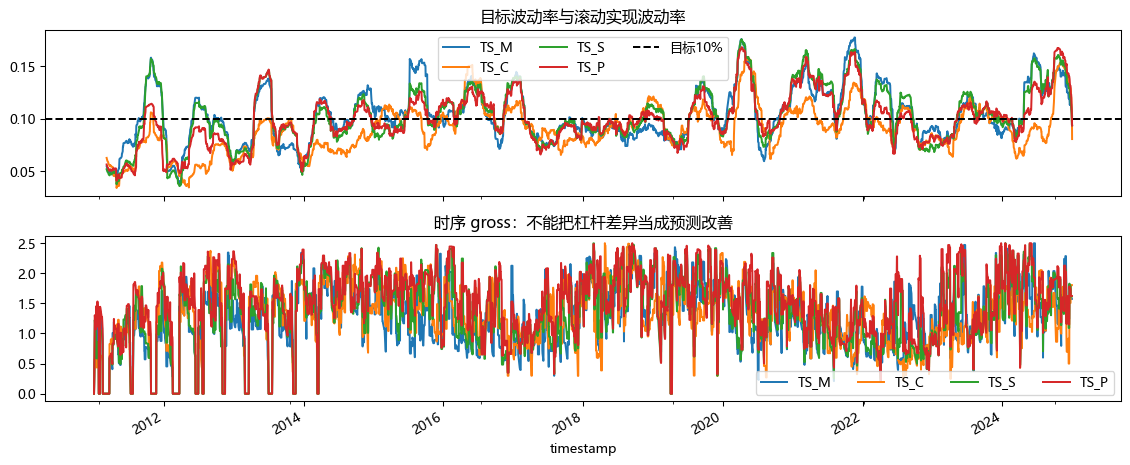

In [20]:
# 风险和实施审计：目标不等于实际，封顶与协方差修复是研究事实。
risk_rows=[]
for name,result in results.items():
    gross=result.exposures.gross_exposure
    row={'name':name,'mean_gross':gross.mean(),'max_gross':gross.max(),
         'mean_net':result.exposures.net_exposure.mean(),'max_abs_net':result.exposures.net_exposure.abs().max(),
         'realized_annual_vol':result.performance.loc['proxy_net','annualized_volatility'],
         'max_product_weight':result.target_weights.abs().max(),'warning_count':len(result.warnings)}
    risk=result.risk
    for col in ['ex_ante_final_volatility','scaling_factor','pairwise_missing','clipped_eigen_count']:
        if col in risk:
            row[col+'_mean']=pd.to_numeric(risk[col],errors='coerce').mean()
    risk_rows.append(row)
risk_audit=pd.DataFrame(risk_rows).set_index('name')
display(risk_audit.round(4))
risk_audit.to_parquet(RUN_ROOT/'risk_audit.parquet')
fig,axes=plt.subplots(2,1,figsize=(12,5),sharex=True)
for name in ['TS_M','TS_C','TS_S','TS_P']:
    result=results[name]
    (result.portfolio_returns.proxy_net_return.rolling(60,min_periods=40).std()*np.sqrt(PROTOCOL['annualization'])).plot(ax=axes[0],label=name)
    result.exposures.gross_exposure.plot(ax=axes[1],label=name)
axes[0].axhline(PROTOCOL['risk']['target_volatility'],color='black',ls='--',label='目标10%')
axes[0].set_title('目标波动率与滚动实现波动率');axes[0].legend(ncol=3)
axes[1].set_title('时序 gross：不能把杠杆差异当成预测改善');axes[1].legend(ncol=4);plt.tight_layout();plt.show()


## 12．研究决策与完整性验收

这里不预写“组合有效”的结论。下方文字根据实际主检验、成本和集中度结果生成，读者仍应结合前面的完整证据审阅。

本 notebook 没有建模实际成交、涨跌停无法成交、容量冲击、精确手续费、整数手数和保证金。收盘数据发布时间与可交易价格尚需专门验证。排名多空的净名义敞口零也不等于商品市场 beta 或板块风险为零。

下一阶段可以按相同协议加入新因子，但不能用 2025—2026 年结果修订本次方法。最终保留样本应由整个多因子框架另行冻结协议后再使用。

目标波动率在计划调仓日估计并应用，非调仓日不会因最新估计变化自动缩放；gross 上限、单品种上限和强制退出也会使实际风险偏离目标。这些偏离是已声明配方的行为，需要结合审计表解释。


In [21]:
conclusions=['### 基于本次实际结果的有限结论']
for row in primary_inference.itertuples(index=False):
    conclusions.append(f'- **{row.new} 相对 {row.base}**：Sharpe 差 {row.delta_sharpe:.3f}，家族校正区间 [{row.ci_low:.3f}, {row.ci_high:.3f}]。判断：{row.decision}。')
for profile in SPECS:
    m,c=relations.loc[relations.profile.eq(profile),'return_corr'].iloc[0],fixed_summary.loc[f'{profile}_P','sharpe']-fixed_summary.loc[f'{profile}_S','sharpe']
    conclusions.append(f'- {profile} 两单因子收益相关性为 {m:.3f}；P 相对 S 的 Sharpe 差为 {c:.3f}。它反映成分持仓、抵消和风险处理的共同结果，不能单独归因为新增预测信息。')
    selected=selections.loc[selections.profile.eq(profile)&selections.path.eq('S')]
    conclusions.append(f'- {profile} 自适应 S 在 {len(selected)} 个测试年度选择了 {selected.candidate_id.nunique()} 个不同配置。该结果包含参数选择，不能替代同参数的收获范式对照。')
for profile in SPECS:
    s=fixed_summary.loc[f'{profile}_S','sharpe']
    c=fixed_summary.loc[f'{profile}_C','sharpe']
    adaptive=adaptive_summary.loc[f'{profile}_S_adaptive','sharpe']
    stress=cost_table.loc[cost_table.name.eq(f'{profile}_S')&cost_table.cost_bps.eq(3),'sharpe'].iloc[0]
    conclusions.append(f'- {profile} 固定信号组合 Sharpe {s:.3f}，展期单因子 {c:.3f}，年度择优信号组合 {adaptive:.3f}；3 bp 成本下固定组合为 {stress:.3f}。更复杂的选择没有被预设为必然改善。')
conclusions.extend(['', '这些判断仅适用于已冻结的市场、信号、约束和开发期历史。区间不能修复此前探索的选择偏差；非显著不等于证明没有信息。',
    '策略收益改善、预测关系和经济机制是不同层次的证据；目标波动率与理想化成交假设还需要进入后续实施验证。'])
display(Markdown('\n'.join(conclusions)))
# 结论正文同时保存在结果区，notebook 中仍保留全部文本和图像。
(RUN_ROOT/'conclusions.md').write_text('\n'.join(conclusions),encoding='utf-8')
replays=pd.DataFrame([verify_snapshot(RUN_ROOT/'fixed'/name) for name in results])
display(replays)
assert replays.max_absolute_error.max() <= 1e-10
assert_development_only(fixed_returns,common_eligible,labels)
assert len(selections)==2*4*(PROTOCOL['last_test_year']-PROTOCOL['first_test_year']+1)
assert len(primary_inference)==4
# 图表只由本 notebook 生成；所有最终结论与实际结果同处一份文件。
acceptance={'protocol':PROTOCOL_ID,'code':CODE_ID,'input':DATA_ID,'holdout_used':False,
    'last_input':str(raw_returns.index.max()),'primary_comparisons':len(primary_inference),
    'validation_records':len(validation_table),'selections':len(selections),
    'snapshot_max_error':float(replays.max_absolute_error.max()),
    'challenge_errors':int(challenge_table.status.ne('ok').sum()+actual_table.status.ne('ok').sum()+leave_table.status.ne('ok').sum()),
    'elapsed_seconds':time.perf_counter()-STARTED}
save_json(RUN_ROOT/'acceptance.json',acceptance)
display(pd.Series(acceptance).to_frame('验收事实'))
print('研究完成。全部证据与重放输入：',RUN_ROOT)

# 原始输入快照与实际持仓快照都须通过校验；失败不能宣布完成。
for file,expected in input_hashes.items():
    assert hashlib.sha256((INPUT_ROOT/file).read_bytes()).hexdigest()==expected
assert acceptance['challenge_errors']==0, '预设挑战存在错误，需要检查并明确处理'
assert primary_inference.valid_reps.eq(PROTOCOL['bootstrap']['reps']).all()
acceptance.update(input_files_verified=len(input_hashes),runtime=runtime_versions,code_snapshot='code_snapshot.json')
save_json(RUN_ROOT/'acceptance.json',acceptance)

### 基于本次实际结果的有限结论
- **CS_S 相对 CS_M**：Sharpe 差 0.512，家族校正区间 [0.025, 0.989]。判断：改善且达到教学幅度。
- **CS_S 相对 CS_C**：Sharpe 差 -0.249，家族校正区间 [-0.795, 0.286]。判断：证据不足或幅度较小。
- **TS_S 相对 TS_M**：Sharpe 差 0.399，家族校正区间 [-0.040, 0.811]。判断：证据不足或幅度较小。
- **TS_S 相对 TS_C**：Sharpe 差 -0.139，家族校正区间 [-0.804, 0.553]。判断：证据不足或幅度较小。
- CS 两单因子收益相关性为 0.019；P 相对 S 的 Sharpe 差为 0.082。它反映成分持仓、抵消和风险处理的共同结果，不能单独归因为新增预测信息。
- CS 自适应 S 在 14 个测试年度选择了 9 个不同配置。该结果包含参数选择，不能替代同参数的收获范式对照。
- TS 两单因子收益相关性为 -0.063；P 相对 S 的 Sharpe 差为 0.182。它反映成分持仓、抵消和风险处理的共同结果，不能单独归因为新增预测信息。
- TS 自适应 S 在 14 个测试年度选择了 9 个不同配置。该结果包含参数选择，不能替代同参数的收获范式对照。
- CS 固定信号组合 Sharpe 0.881，展期单因子 1.130，年度择优信号组合 0.669；3 bp 成本下固定组合为 0.757。更复杂的选择没有被预设为必然改善。
- TS 固定信号组合 Sharpe 1.071，展期单因子 1.210，年度择优信号组合 0.938；3 bp 成本下固定组合为 0.958。更复杂的选择没有被预设为必然改善。

这些判断仅适用于已冻结的市场、信号、约束和开发期历史。区间不能修复此前探索的选择偏差；非显著不等于证明没有信息。
策略收益改善、预测关系和经济机制是不同层次的证据；目标波动率与理想化成交假设还需要进入后续实施验证。

,snapshot,max_absolute_error,files_verified
0,CS_M,0.0,12
1,CS_C,0.0,12
2,CS_S,0.0,12
3,TS_M,0.0,12
4,TS_C,0.0,12
5,TS_S,0.0,12
6,CS_P,0.0,15
7,TS_P,0.0,15


,验收事实
protocol,1fc83d955453a84174bc0f955b0ee73542b1829bc0fd41...
code,8502926b247b251ced3c0c46becd8f33f877c0c51b333b...
input,60ec190500a3ca5b4e37a640331783f41f8c030c29364b...
holdout_used,False
last_input,2024-12-31 00:00:00
primary_comparisons,4
validation_records,1680
selections,112
snapshot_max_error,0.0
challenge_errors,0


研究完成。全部证据与重放输入： D:\量化策略\CTA策略\early-bird-alpha\research\artifacts\single_to_two_factor\1fc83d955453\5f79da03c7de4dd7
